### Uses X_train_scaled.csv and X_test_scaled.csv
### Uses class_weight = "balanced" to battle class imbalance
### Uses PR-AUC tuning since accuracy is useless
### 5-fold cross validation on train
### Test set touched once at the very end

In [1]:
from pathlib import Path
import json
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                            precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, learning_curve

os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
DATA_DIR = Path("../data/processed")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### Loading scaled data and making sure everything matches up

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_scaled.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["hit"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["hit"]
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(X_train[c]) for c in X_train.columns)
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Hit rate: Train {y_train.mean():.1%}, Test {y_test.mean():.1%} (imbalance ratio in train {(y_train == 0).sum() / (y_train == 1).sum():.1f}:1)")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
#finds the threshold with the highest F1 on these predictions
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return f1[i], thr[i]

Train (45491, 25), Test (21760, 25)
Hit rate: Train 10.9%, Test 5.6% (imbalance ratio in train 8.2:1)


### Using balanced class weights + 5-fold CV

In [3]:
baseline = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)
oof = cross_val_predict(baseline, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
print(f"Baseline Cross Validation: PR-AUC {average_precision_score(y_train, oof):.3f}     ROC-AUC {roc_auc_score(y_train, oof):.3f}")

Baseline Cross Validation: PR-AUC 0.526     ROC-AUC 0.847


### Hyperparameter tuning

In [4]:
#liblinear supports both l1 and l2 penalties for a binary problem
lr = LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000)
parameter_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"]}
grid = GridSearchCV(lr, parameter_grid, scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
cv = pd.DataFrame(grid.cv_results_)
print("Best parameter:", grid.best_params_, f"     CV PR-AUC = {grid.best_score_:.4f}")


Best parameter: {'C': 100, 'penalty': 'l2'}      CV PR-AUC = 0.5267


### Checking for overfitting/underfitting

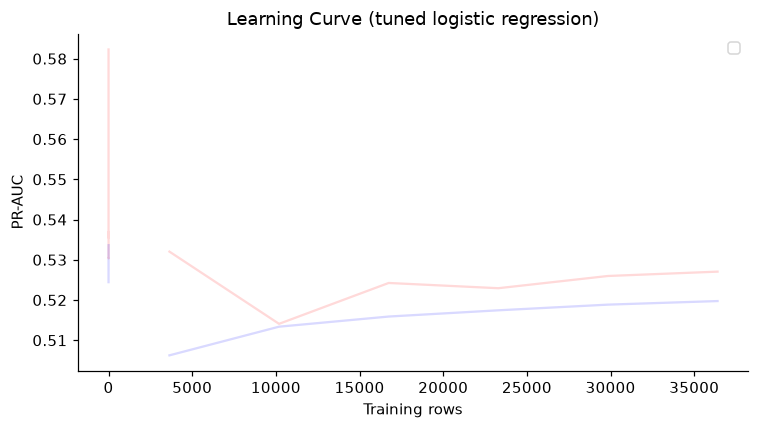

In [5]:
best_model = grid.best_estimator_
sizes, tr_sc, va_sc = learning_curve(best_model, X_train, y_train, cv=skf, scoring="average_precision",
                                     train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
fig, ax = plt.subplots(figsize=(7, 4))
for sc, label, color in [(tr_sc, "Train", "red"), (va_sc, "Validation", "blue")]:
    ax.plot(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=.15)
ax.set_xlabel("Training rows")
ax.set_ylabel("PR-AUC")
ax.set_title("Learning Curve (tuned logistic regression)")
ax.legend()
plt.tight_layout()
plt.show()

More training data does not close any gap which means there is high bias, and the model underfits. (RED = TRAIN, BLUE = VALIDATION)

In [6]:
oof = cross_val_predict(best_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
f1_oof, THRESHOLD = best_f1_threshold(y_train, oof)
print(f"Optimal F1 threshold from train CV:  {THRESHOLD:.3f}     (CV F1 = {f1_oof:.3f})")  

Optimal F1 threshold from train CV:  0.727     (CV F1 = 0.525)


In [7]:
p_test = best_model.predict_proba(X_test)[:, 1]
def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"threshold": thr, "precision": precision_score(y, pred), "recall": recall_score(y, pred), "F1": f1_score(y,pred),
           "accuracy": (pred == y).mean()}

final = pd.DataFrame({
    "threshold 0.5": report(y_test, p_test, 0.5),
    f"threshold {THRESHOLD:.2f} (CV f1-optimal)": report(y_test, p_test, THRESHOLD)
}).T

print(f"Test PR-AUC {average_precision_score(y_test, p_test):.3f}     Test ROC-AUC {roc_auc_score(y_test, p_test):.3f}")
final.round(3)

Test PR-AUC 0.434     Test ROC-AUC 0.855


,threshold,precision,recall,F1,accuracy
threshold 0.5,0.500,0.197,0.747,0.311,0.815
threshold 0.73 (CV f1-optimal),0.727,0.342,0.552,0.423,0.915


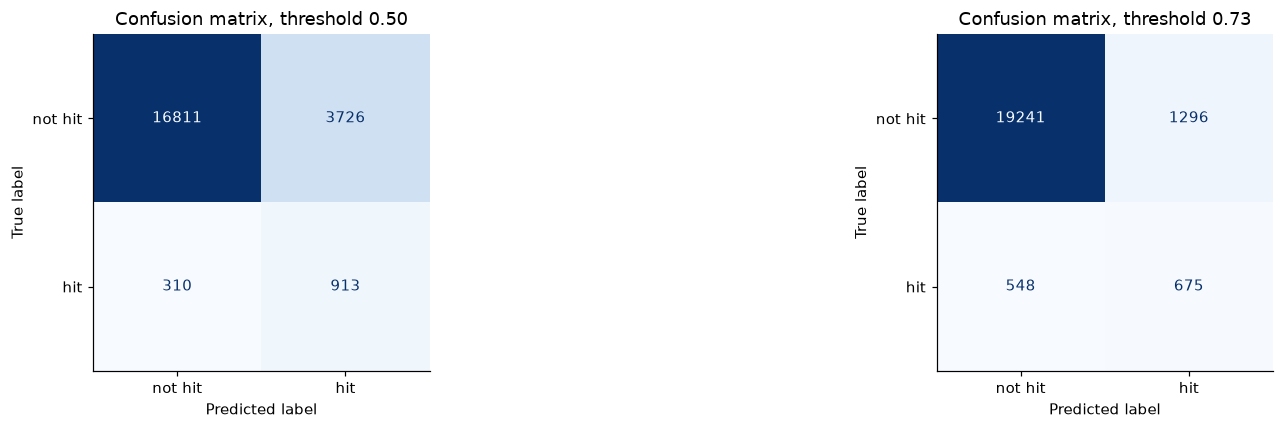

In [8]:
fig, axes = plt.subplots(1,2, figsize=(18,4))
for ax, thr in zip(axes, [0.5, THRESHOLD]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix, threshold {thr:.2f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [9]:
results = {
    "model": "logistic_regression",
    "preprocessing": "scaled data from preprocessing.ipynb, class_weight=balanced",
    "best_params": {k: v for k, v in grid.best_params_.items()},
    "cv_pr_auc": float(grid.best_score_),
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_roc_auc": float(roc_auc_score(y_test, p_test)),
    "test_random_guesser_pr_auc": float(y_test.mean()), #what a random guesser would get 
    "threshold_cv_f1_optimal": float(THRESHOLD),
    "test_at_0.5": {k: float(v) for k, v in report(y_test, p_test, 0.5).items()},
    "test_at_cv_threshold": {k: float(v) for k, v in report(y_test, p_test, THRESHOLD).items()},
}
with open(DATA_DIR / "logreg_results.json", "w") as f:
    json.dump(results, f, indent=1)
print(json.dumps(results, indent=1))

{
 "model": "logistic_regression",
 "preprocessing": "scaled data from preprocessing.ipynb, class_weight=balanced",
 "best_params": {
  "C": 100,
  "penalty": "l2"
 },
 "cv_pr_auc": 0.5266862642692105,
 "test_pr_auc": 0.43370988987031045,
 "test_roc_auc": 0.8545961020197238,
 "test_random_guesser_pr_auc": 0.05620404411764706,
 "threshold_cv_f1_optimal": 0.7273332920880755,
 "test_at_0.5": {
  "threshold": 0.5,
  "precision": 0.19680965725371846,
  "recall": 0.7465249386753884,
  "F1": 0.3114977823268509,
  "accuracy": 0.8145220588235295
 },
 "test_at_cv_threshold": {
  "threshold": 0.7273332920880755,
  "precision": 0.3424657534246575,
  "recall": 0.5519215044971382,
  "F1": 0.4226675015654352,
  "accuracy": 0.9152573529411765
 }
}
